In [6]:
%pip install matplotlib

  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.3 MB 9.4 MB/s eta 0:00:01
   ---------------- ----------------------- 3.9/9.3 MB 10.2 MB/s eta 0:00:01
   ------------------------- -------------- 6.0/9.3 MB 10.5 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.3 MB 10.6 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 10.4 MB/s  0:00:00
Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl (225 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 11.4 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ----------- ---------------------------- 2.1/7.3 MB 13.1 MB/s eta 0:00:01
   --


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install pyarrow

   ---------------------------------------- 0.0/29.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/29.0 MB ? eta -:--:--
   - -------------------------------------- 1.3/29.0 MB 3.1 MB/s eta 0:00:10
   -- ------------------------------------- 1.6/29.0 MB 3.2 MB/s eta 0:00:09
   --- ------------------------------------ 2.4/29.0 MB 2.8 MB/s eta 0:00:10
   --- ------------------------------------ 2.6/29.0 MB 2.6 MB/s eta 0:00:11
   --- ------------------------------------ 2.9/29.0 MB 2.4 MB/s eta 0:00:11
   ---- ----------------------------------- 3.1/29.0 MB 2.2 MB/s eta 0:00:12
   ---- ----------------------------------- 3.4/29.0 MB 2.2 MB/s eta 0:00:12
   ----- ---------------------------------- 3.7/29.0 MB 2.1 MB/s eta 0:00:13
   ----- ---------------------------------- 3.9/29.0 MB 2.0 MB/s eta 0:00:13
   ------ --------------------------------- 4.5/29.0 MB 1.9 MB/s eta 0:00:13
   ------ --------------------------------- 4.7/29.0 MB 1.9 MB/s eta 0:00:13
   ------ ---


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Load one session and both CSV files

In [2]:
from pathlib import Path

import pandas as pd
from IPython.display import display

export_dir = Path("data/pupil_adhd_data/export")
raw_dir = export_dir / "raw"

session_paths = sorted(raw_dir.rglob("*.parquet"))

if not session_paths:
    raise FileNotFoundError(
        f"No Parquet files found in {raw_dir.resolve()}. "
        f"Current working directory: {Path.cwd()}"
    )

session_path = session_paths[0]
samples = pd.read_parquet(session_path)
trials = pd.read_csv(export_dir / "trials.csv")
metadata = pd.read_csv(export_dir / "meta.csv")

print("Parquet files found:", len(session_paths))
print("Selected session file:", session_path)

for name, table in [
    ("Session samples", samples),
    ("Trial outcomes", trials),
    ("Session metadata", metadata),
]:
    print(f"\n{name}: {table.shape[0]:,} rows, {table.shape[1]} columns")
    print(table.dtypes.to_string())
    display(table.head(5))

Parquet files found: 67
Selected session file: data\pupil_adhd_data\export\raw\session_01.parquet

Session samples: 1,369,480 rows, 5 columns
time        float64
diameter    float64
x           float64
y           float64
event       float64


,time,diameter,x,y,event
0,NaN,NaN,NaN,NaN,0.0
1,NaN,NaN,NaN,NaN,0.0
2,NaN,NaN,NaN,NaN,0.0
3,NaN,NaN,NaN,NaN,0.0
4,NaN,NaN,NaN,NaN,0.0



Trial outcomes: 10,720 rows, 7 columns
Trial             int64
Load              int64
Distractor        int64
CorrResponse      int64
Perform         float64
Rtime           float64
session           int64


,Trial,Load,Distractor,CorrResponse,Perform,Rtime,session
0,1,1,5,2,1.0,1497.0,1
1,2,1,3,2,NaN,NaN,1
2,3,2,6,1,0.0,1034.0,1
3,4,2,3,2,1.0,924.0,1
4,5,1,6,2,1.0,907.0,1



Session metadata: 67 rows, 29 columns
session                           int64
subject                           int64
group                               str
age                               int64
Age                             float64
WISC                                str
Gender                              str
Information                     float64
Similarities                    float64
Arithmetic                      float64
Vocabulary                      float64
Comprehension                   float64
Digit_span                      float64
Verbal_score                      int64
Verbal_IQ                       float64
Picture_completion              float64
Picturearrangement              float64
Block_design                    float64
Object_assembly                 float64
Cues                            float64
Mazes                           float64
Symbol_search                   float64
Performance_score                 int64
Performance_IQ                  float64
V

,session,subject,group,age,Age,WISC,Gender,Information,Similarities,Arithmetic,...,Cues,Mazes,Symbol_search,Performance_score,Performance_IQ,Verbal_comprehension,Perceptual_organization,Processing_speed,Freedom_from_distractibility,Full_Scale_IQ
0,1,1,off-ADHD,10,9.0,III,M,12.0,15.0,10.0,...,8.0,8.0,11.0,54,109.0,106.0,106.0,97.0,NaN,106.0
1,2,2,off-ADHD,9,9.0,III,F,15.0,15.0,11.0,...,10.0,10.0,12.0,68,126.0,132.0,129.0,106.0,108.0,134.0
2,3,3,off-ADHD,9,8.0,III,M,9.0,8.0,6.0,...,11.0,5.0,10.0,42,89.0,88.0,86.0,103.0,74.0,88.0
3,4,4,off-ADHD,12,11.0,R,M,10.0,12.0,8.0,...,12.0,11.0,0.0,53,102.0,NaN,NaN,NaN,NaN,102.0
4,5,5,off-ADHD,10,9.0,III,M,9.0,9.0,10.0,...,7.0,8.0,7.0,46,95.0,94.0,99.0,83.0,NaN,94.0


Extract the pupil sequence for one trial

Samples: 500
Missing pupil values: 0
Zero pupil values: 0


,Trial,Load,Distractor,CorrResponse,Perform,Rtime,session
0,1,1,5,2,1.0,1497.0,1


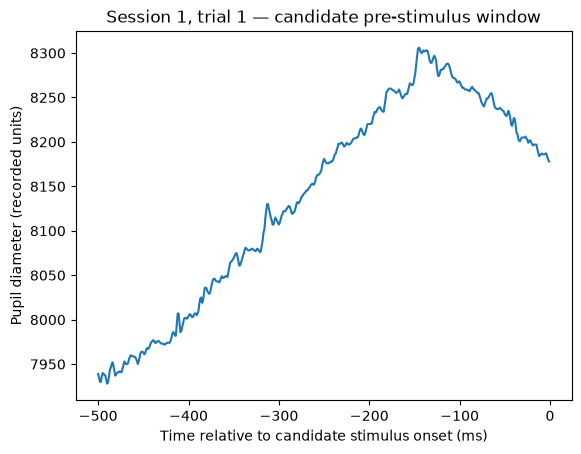

In [3]:
stimulus_onset = 4_445_848  # Candidate onset for session 1, trial 1

window = (
    samples.loc[
        samples["time"].ge(stimulus_onset - 500)
        & samples["time"].lt(stimulus_onset),
        ["time", "diameter"],
    ]
    .sort_values("time")
    .copy()
)

if window.empty:
    raise ValueError("No samples found in the pre-stimulus window.")

window["relative_time_ms"] = window["time"] - stimulus_onset

print("Samples:", len(window))
print("Missing pupil values:", window["diameter"].isna().sum())
print("Zero pupil values:", window["diameter"].eq(0).sum())

window.plot(
    x="relative_time_ms",
    y="diameter",
    xlabel="Time relative to candidate stimulus onset (ms)",
    ylabel="Pupil diameter (recorded units)",
    title="Session 1, trial 1 — candidate pre-stimulus window",
    legend=False,
)

display(trials.loc[trials["session"].eq(1) & trials["Trial"].eq(1)])

Check the matching outcome in trials.csv

In [4]:
# Candidate trial starts from the event rows you inspected
candidate_starts = [4_445_848, 4_453_865, 4_460_516, 4_468_532]

checks = []

for trial_number, (start, end) in enumerate(
    zip(candidate_starts, candidate_starts[1:]), start=1
):
    events = samples.loc[
        samples["time"].ge(start)
        & samples["time"].lt(end)
        & samples["event"].isin([7, 10]),
        ["time", "event"],
    ].sort_values("time")

    event_7 = events.loc[events["event"].eq(7), "time"]
    event_10 = events.loc[events["event"].eq(10), "time"]

    event_gap = (
        event_10.iloc[0] - event_7.iloc[0]
        if len(event_7) == len(event_10) == 1
        else float("nan")
    )

    checks.append({"Trial": trial_number, "event_gap_ms": event_gap})

session_trials = trials.loc[
    trials["session"].eq(1), ["Trial", "Perform", "Rtime"]
]

display(pd.DataFrame(checks).merge(
    session_trials, on="Trial", how="left", validate="one_to_one"
))

,Trial,event_gap_ms,Perform,Rtime
0,1,1497.0,1.0,1497.0
1,2,NaN,NaN,NaN
2,3,1034.0,0.0,1034.0


In [5]:
events = (
    samples.loc[
        samples["time"].notna() & samples["event"].isin([1, 2, 7]),
        ["time", "event"],
    ]
    .sort_values("time", kind="stable")
)

rows = []
stimuli = []

for time, event in events.itertuples(index=False, name=None):
    if event in (1, 2):
        stimuli.append((time, int(event)))
    else:  # event 7
        rows.append({
            "Trial": len(rows) + 1,
            "n_stimuli": len(stimuli),
            "stimulus_codes": [code for _, code in stimuli],
            "first_stimulus_candidate_ms": stimuli[0][0] if stimuli else None,
        })
        stimuli = []

onsets = pd.DataFrame(rows)

print("Event groups:", len(onsets))
print("Trials in CSV:", trials["session"].eq(1).sum())
print("Groups with exactly 3 stimuli:", onsets["n_stimuli"].eq(3).sum())
print("Stimuli left after the last event 7:", len(stimuli))

display(onsets.head(10))
display(onsets.loc[onsets["n_stimuli"].ne(3)])

Event groups: 160
Trials in CSV: 160
Groups with exactly 3 stimuli: 160
Stimuli left after the last event 7: 0


,Trial,n_stimuli,stimulus_codes,first_stimulus_candidate_ms
0,1,3,"[1, 1, 1]",4445848.0
1,2,3,"[1, 1, 1]",4453865.0
2,3,3,"[2, 2, 2]",4460516.0
3,4,3,"[2, 2, 2]",4468532.0
4,5,3,"[1, 1, 1]",4476550.0
5,6,3,"[2, 2, 2]",4484567.0
6,7,3,"[2, 2, 2]",4492584.0
7,8,3,"[1, 1, 1]",4500601.0
8,9,3,"[2, 2, 2]",4508619.0
9,10,3,"[2, 2, 2]",4516619.0


,Trial,n_stimuli,stimulus_codes,first_stimulus_candidate_ms


In [6]:
import numpy as np

session_id = 1
window_ms = 500

# Match candidate onsets to the trial outcomes.
session_trials = trials.loc[
    trials["session"].eq(session_id), ["Trial", "Perform", "Rtime"]
]

trial_table = onsets.merge(
    session_trials,
    on="Trial",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

if not trial_table["_merge"].eq("both").all():
    display(trial_table.loc[trial_table["_merge"].ne("both")])
    raise ValueError("Some candidate onsets and CSV trials did not match.")

trial_table = trial_table.drop(columns="_merge").sort_values("Trial")

# Index pupil measurements by their recorded timestamp.
pupil_by_time = (
    samples.loc[samples["time"].notna(), ["time", "diameter"]]
    .set_index("time")["diameter"]
    .sort_index()
)

if not pupil_by_time.index.is_unique:
    raise ValueError("Duplicate timestamps found. Inspect them before extracting windows.")

sequences = []
kept_rows = []
quality_rows = []

for row in trial_table.itertuples():
    onset = row.first_stimulus_candidate_ms
    expected_times = onset + np.arange(-window_ms, 0)
    pupil = pupil_by_time.reindex(expected_times).to_numpy(dtype=np.float32)

    missing = int((~np.isfinite(pupil)).sum())
    zeros = int((pupil == 0).sum())
    keep = missing == 0 and zeros == 0

    quality_rows.append({
        "Trial": row.Trial,
        "missing_or_nonfinite": missing,
        "zeros": zeros,
        "kept": keep,
    })

    if keep:
        sequences.append(pupil[:, None])
        kept_rows.append(row.Index)

quality = pd.DataFrame(quality_rows)
X = np.stack(sequences) if sequences else np.empty((0, window_ms, 1))
trial_info = trial_table.loc[kept_rows].reset_index(drop=True)

print("X shape (trials, time steps, features):", X.shape)
print("Kept:", len(X), "/", len(trial_table))
display(trial_info.head())
display(quality.loc[~quality["kept"]].head(15))

X shape (trials, time steps, features): (126, 500, 1)
Kept: 126 / 160


,Trial,n_stimuli,stimulus_codes,first_stimulus_candidate_ms,Perform,Rtime
0,1,3,"[1, 1, 1]",4445848.0,1.0,1497.0
1,2,3,"[1, 1, 1]",4453865.0,NaN,NaN
2,3,3,"[2, 2, 2]",4460516.0,0.0,1034.0
3,5,3,"[1, 1, 1]",4476550.0,1.0,907.0
4,6,3,"[2, 2, 2]",4484567.0,0.0,1469.0


,Trial,missing_or_nonfinite,zeros,kept
3,4,0,73,False
7,8,0,131,False
9,10,0,183,False
20,21,500,0,False
40,41,500,0,False
54,55,0,121,False
60,61,500,0,False
61,62,0,118,False
62,63,0,38,False
67,68,0,68,False


In [7]:
recorded_times = pupil_by_time.index.sort_values()

fully_missing = quality.loc[
    quality["missing_or_nonfinite"].eq(500), ["Trial"]
].merge(
    trial_table[["Trial", "first_stimulus_candidate_ms"]],
    on="Trial",
    validate="one_to_one",
)

rows = []
for trial, onset in fully_missing.itertuples(index=False, name=None):
    pos = recorded_times.searchsorted(onset)
    previous = recorded_times[pos - 1] if pos > 0 else np.nan
    at_or_after = recorded_times[pos] if pos < len(recorded_times) else np.nan

    rows.append({
        "Trial": trial,
        "previous_sample_relative_ms": previous - onset,
        "first_sample_at_or_after_ms": at_or_after - onset,
    })

display(pd.DataFrame(rows))

,Trial,previous_sample_relative_ms,first_sample_at_or_after_ms
0,21,-117513.0,0.0
1,41,-75835.0,0.0
2,61,-210488.0,0.0
3,81,-47859.0,0.0
4,101,-382579.0,0.0
5,121,-60544.0,0.0
6,141,-38364.0,0.0


In [8]:
review = trial_table[["Trial", "Perform"]].merge(
    quality[["Trial", "kept"]],
    on="Trial",
    validate="one_to_one",
)

review["outcome"] = (
    review["Perform"]
    .map({1: "Correct", 0: "Incorrect"})
    .fillna("Missing or other")
)

summary = review.groupby("outcome").agg(
    total=("kept", "size"),
    kept=("kept", "sum"),
)
summary["excluded"] = summary["total"] - summary["kept"]
summary["kept_pct"] = (100 * summary["kept"] / summary["total"]).round(1)

display(summary)

,total,kept,excluded,kept_pct
outcome,,,,
Correct,94,72,22,76.6
Incorrect,53,41,12,77.4
Missing or other,13,13,0,100.0


In [9]:
# Keep trials with a known correct/incorrect outcome.
known_outcome = trial_info["Perform"].isin([0, 1]).to_numpy()

# Use the same filter for the sequences and their matching trial rows.
X_error = X[known_outcome]
trial_info_error = trial_info.loc[known_outcome].reset_index(drop=True)
y_error = trial_info_error["Perform"].eq(0).to_numpy(dtype=np.int64)

print("X_error shape:", X_error.shape)
print("y_error shape:", y_error.shape)
print("Correct (0):", (y_error == 0).sum())
print("Incorrect (1):", (y_error == 1).sum())

display(trial_info_error[["Trial", "Perform", "Rtime"]].assign(y=y_error).head())

X_error shape: (113, 500, 1)
y_error shape: (113,)
Correct (0): 72
Incorrect (1): 41


,Trial,Perform,Rtime,y
0,1,1.0,1497.0,0
1,3,0.0,1034.0,1
2,5,1.0,907.0,0
3,6,0.0,1469.0,1
4,7,1.0,1406.0,0


In [10]:
session_02_path = next(raw_dir.rglob("session_02.parquet"), None)
if session_02_path is None:
    raise FileNotFoundError("Could not find session_02.parquet.")

samples_02 = pd.read_parquet(session_02_path)
trials_02 = trials.loc[trials["session"].eq(2)]

events_02 = (
    samples_02.loc[
        samples_02["time"].notna() & samples_02["event"].isin([1, 2, 7]),
        ["time", "event"],
    ]
    .sort_values("time", kind="stable")
)

# Assign each stimulus to the next event 7.
trial_index = events_02["event"].eq(7).shift(fill_value=False).cumsum() + 1
groups_02 = events_02.groupby(trial_index)["event"].agg(list)

valid_groups = groups_02.map(
    lambda codes: len(codes) == 4 and codes[-1] == 7
)

print("Event groups:", len(groups_02))
print("Trials in CSV:", len(trials_02))
print("Groups with 3 stimuli followed by event 7:", valid_groups.sum())
display(groups_02.loc[~valid_groups])

Event groups: 160
Trials in CSV: 160
Groups with 3 stimuli followed by event 7: 160


Series([], Name: event, dtype: object)

In [3]:
%pip install torch

  Using cached torch-2.15.0-cp311-cp311-win_amd64.whl.metadata (36 kB)
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/126.7 MB 5.6 MB/s eta 0:00:23
    --------------------------------------- 1.8/126.7 MB 6.3 MB/s eta 0:00:20
   - -------------------------------------- 3.4/126.7 MB 6.7 MB/s eta 0:00:19
   - -------------------------------------- 5.0/126.7 MB 7.0 MB/s eta 0:00:18
   -- ------------------------------------- 6.6/126.7 MB 7.1 MB/s eta 0:00:18
   -- ------------------------------------- 7.6/126.7 MB 7.0 MB/s eta 0:00:17
   -- ------------------------------------- 8.9/126.7 MB 6.8 MB/s eta 0:00:18
   --- ------------------------------------ 10.2/126.7 MB 6.6 MB/s eta 0:00:18
   --- ------------------------------------ 11.8/126.7 MB 6.7 MB/s eta 0:00:18
   ---- ----------------------------------- 13.4/126.7 MB 6.8 MB/s eta 0:00:17
   ---- ----------------------------------- 14.9/126.7 MB 6.9 MB/s eta 0:00


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import torch
from torch import nn

torch.manual_seed(42)

# Normalize pupil diameter for this single-session training check.
X_train = torch.tensor(X_error, dtype=torch.float32)
X_train = (X_train - X_train.mean()) / X_train.std(unbiased=False).clamp_min(1e-6)
y_train = torch.tensor(y_error, dtype=torch.float32)

lstm = nn.LSTM(input_size=1, hidden_size=16, batch_first=True)
classifier = nn.Linear(16, 1)

optimizer = torch.optim.Adam(
    [*lstm.parameters(), *classifier.parameters()], lr=0.005
)
loss_fn = nn.BCEWithLogitsLoss()

for epoch in range(1, 6):
    optimizer.zero_grad()

    _, (hidden, _) = lstm(X_train)
    logits = classifier(hidden[-1]).squeeze(-1)
    loss = loss_fn(logits, y_train)

    loss.backward()
    optimizer.step()

    print(f"Epoch {epoch}: training loss = {loss.item():.4f}")

with torch.no_grad():
    _, (hidden, _) = lstm(X_train[:5])
    probabilities = classifier(hidden[-1]).squeeze(-1).sigmoid()

display(
    trial_info_error[["Trial"]].head(5).assign(
        predicted_error_probability=probabilities.numpy(),
        actual_error=y_error[:5],
    )
)

Epoch 1: training loss = 0.7018
Epoch 2: training loss = 0.6953
Epoch 3: training loss = 0.6895
Epoch 4: training loss = 0.6843
Epoch 5: training loss = 0.6796


,Trial,predicted_error_probability,actual_error
0,1,0.529805,0
1,3,0.531910,1
2,5,0.511092,0
3,6,0.520585,1
4,7,0.522105,0


2nd window

In [12]:
# Use the same session and trial order as the earlier extraction.
probe_times = (
    samples.loc[samples["event"].eq(7) & samples["time"].notna(), "time"]
    .sort_values()
    .to_numpy()
)

during_task = trial_table.sort_values("Trial").reset_index(drop=True).copy()

if len(probe_times) != len(during_task):
    raise ValueError("The number of probe events does not match the number of trials.")

during_task["probe_ms"] = probe_times
during_task["duration_ms"] = (
    during_task["probe_ms"] - during_task["first_stimulus_candidate_ms"]
)

if during_task["duration_ms"].le(0).any():
    raise ValueError("A probe timestamp is at or before its first stimulus.")

# Extract [first dot onset, probe onset) on the original 1 ms grid.
task_sequences = {}
quality_rows = []

for row in during_task.itertuples(index=False):
    times = np.arange(row.first_stimulus_candidate_ms, row.probe_ms)
    pupil = pupil_by_time.reindex(times).to_numpy(dtype=np.float32)

    invalid = ~np.isfinite(pupil) | (pupil == 0)
    quality_rows.append({
        "Trial": row.Trial,
        "duration_ms": len(pupil),
        "invalid_pct": round(100 * invalid.mean(), 1),
    })
    task_sequences[row.Trial] = pupil

task_quality = pd.DataFrame(quality_rows)
shared_trials = task_quality.loc[
    task_quality["Trial"].isin(trial_info_error["Trial"])
]

display(shared_trials.head(10))
display(shared_trials[["duration_ms", "invalid_pct"]].describe())
print("Trials with the same known outcomes in both windows:", len(shared_trials))

,Trial,duration_ms,invalid_pct
0,1,4950,2.1
2,3,4950,0.0
4,5,4951,0.0
5,6,4950,0.0
6,7,4950,0.0
8,9,4933,3.7
10,11,4951,0.0
11,12,4951,6.1
12,13,4950,3.5
13,14,4950,2.1


,duration_ms,invalid_pct
count,113.000000,113.000000
mean,4940.893805,3.687611
std,35.713234,3.812740
min,4651.000000,0.000000
25%,4935.000000,0.000000
50%,4950.000000,3.200000
75%,4950.000000,5.600000
max,4952.000000,19.100000


Trials with the same known outcomes in both windows: 113


In [14]:
X_during_masked = []
usable_fractions = []

for trial in trial_info_error["Trial"]:
    pupil = task_sequences[trial]

    # Keep the final bin even if it contains fewer than 20 ms.
    padded = np.pad(
        pupil.astype(np.float32),
        (0, (-len(pupil)) % 20),
        constant_values=np.nan,
    )
    bins = padded.reshape(-1, 20)
    valid = np.isfinite(bins) & (bins > 0)
    counts = valid.sum(axis=1)
    bin_sizes = np.minimum(20, len(pupil) - 20 * np.arange(len(bins)))
    usable = counts * 2 >= bin_sizes

    means = np.where(valid, bins, 0).sum(axis=1) / np.maximum(counts, 1)
    means[~usable] = 0

    # Two features per time step: pupil mean and a validity flag.
    X_during_masked.append(np.column_stack([means, usable]).astype(np.float32))
    usable_fractions.append(usable.mean())

print("Trials:", len(X_during_masked))
print("First trial shape:", X_during_masked[0].shape)
print("Lowest percentage of usable bins:", round(100 * min(usable_fractions), 1))

Trials: 113
First trial shape: (248, 2)
Lowest percentage of usable bins: 81.4


In [15]:
from torch.nn.utils.rnn import pack_sequence

torch.manual_seed(42)

# Scale pupil size using only usable bins.
valid_pupil = np.concatenate([
    seq[seq[:, 1] == 1, 0] for seq in X_during_masked
])
mean = valid_pupil.mean()
std = max(valid_pupil.std(), 1e-6)

sequences = []
for seq in X_during_masked:
    seq = seq.copy()
    usable = seq[:, 1] == 1
    seq[usable, 0] = (seq[usable, 0] - mean) / std
    sequences.append(torch.from_numpy(seq))

packed = pack_sequence(sequences, enforce_sorted=False)
targets = torch.tensor(y_error, dtype=torch.float32)

lstm_during = nn.LSTM(input_size=2, hidden_size=16)
classifier_during = nn.Linear(16, 1)
optimizer = torch.optim.Adam(
    [*lstm_during.parameters(), *classifier_during.parameters()], lr=0.005
)
loss_fn = nn.BCEWithLogitsLoss()

for epoch in range(1, 6):
    optimizer.zero_grad()
    _, (hidden, _) = lstm_during(packed)
    logits = classifier_during(hidden[-1]).squeeze(-1)
    loss = loss_fn(logits, targets)
    loss.backward()
    optimizer.step()
    print(f"Epoch {epoch}: training loss = {loss.item():.4f}")

Epoch 1: training loss = 0.6606
Epoch 2: training loss = 0.6584
Epoch 3: training loss = 0.6568
Epoch 4: training loss = 0.6557
Epoch 5: training loss = 0.6550


In [16]:
from sklearn.metrics import roc_auc_score

with torch.no_grad():
    _, (hidden, _) = lstm_during(packed)
    scores = classifier_during(hidden[-1]).squeeze(-1).numpy()

print("Training AUROC:", round(roc_auc_score(y_error, scores), 3))

Training AUROC: 0.555
